# Hand Gesture Recognition — Computer Vision Assignment 1
**Task:** classify hand gestures (peace sign, thumb, stop/open palm, OK sign) from photographs of a **self-collected dataset**.

**Pipeline:** data collection → preprocessing & augmentation → baseline model → improved model → evaluation (accuracy, precision, recall, F1, confusion matrix) → discussion.

> **Note on dataset size.** The assignment asks for 100–200 images per class. The collected set contains only **68 usable photos (13–19 per class)**, so every result below is a *small-data* result and must be read with that in mind (see the Discussion). The pipeline is written so that adding more photos to `hand_gesture_dataset/<class>/` and re-running the notebook is enough to update all numbers.

In [1]:
import os, json, random, io
import numpy as np, cv2
import matplotlib
import matplotlib.pyplot as plt
from collections import Counter
from skimage.feature import hog
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
CLASSES = ['peace', 'thumb', 'stop', 'ok']
os.makedirs('figures', exist_ok=True)

# ---- locate the dataset automatically -------------------------------------------------
# Works if you (a) upload hand_gesture_dataset.zip to Colab WITHOUT unzipping it locally,
# or (b) already have the unpacked folder anywhere under the working directory / Google Drive.
import glob, zipfile

def find_dataset(max_depth=4):
    for base in ['.', '/content', '/content/drive/MyDrive', os.path.expanduser('~')]:
        if not os.path.isdir(base): continue
        for root, dirs, _ in os.walk(base, followlinks=True):
            if all(c in dirs for c in CLASSES):
                return root
            if root.count(os.sep) - base.rstrip(os.sep).count(os.sep) >= max_depth:
                dirs[:] = []
    return None

DATA = find_dataset()
if DATA is None:
    zips = glob.glob('**/hand_gesture_dataset*.zip', recursive=True) + glob.glob('/content/**/hand_gesture_dataset*.zip', recursive=True)
    if not zips:
        try:
            from google.colab import files
            print('Dataset not found -> please select hand_gesture_dataset.zip (do NOT unzip it first)')
            files.upload()
            zips = glob.glob('hand_gesture_dataset*.zip') + glob.glob('/content/hand_gesture_dataset*.zip')
        except ImportError:
            pass
    if zips:
        print('Extracting', zips[0])
        zipfile.ZipFile(zips[0]).extractall('.')
        DATA = find_dataset()
assert DATA is not None, "Dataset folder not found: it must contain the sub-folders peace/, thumb/, stop/, ok/"
print('Using dataset folder:', os.path.abspath(DATA))

Using dataset folder: /home/claude/work/hand_gesture_dataset


## 1. Dataset
Photos were taken with a phone camera, one hand per photo, in **five different sessions** (street asphalt, grey table, grey floor, dark tiled floor, white floor), with different lighting, hand positions, distances and several hands/skin tones. Images were labelled manually and resized so the longer side is ≤768 px.
Classes: **peace** (V sign), **thumb** (thumb extended, other fingers closed), **stop** (open hand, all fingers spread), **ok** (thumb–index circle).
Two photos that were near-duplicates (burst shots) were detected with a perceptual hash and put into the same *group*, so they can never be split between train and test.

total images: 68 | classes: {'peace': 18, 'thumb': 18, 'stop': 19, 'ok': 13} | independent groups: 66


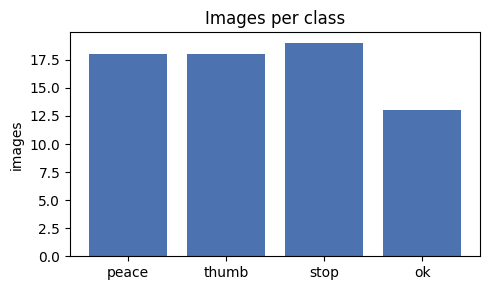

In [2]:
if os.path.exists(f'{DATA}/metadata.json'):
    meta = json.load(open(f'{DATA}/metadata.json'))
else:   # fallback: take labels from folder names, every image is its own group
    labels = {f: c for c in CLASSES for f in sorted(os.listdir(f'{DATA}/{c}')) if f.lower().endswith(('.jpg', '.jpeg', '.png'))}
    meta = {'labels': labels, 'groups': {f: i for i, f in enumerate(labels)}}
files = sorted(meta['labels'])
paths = [f"{DATA}/{meta['labels'][f]}/{f}" for f in files]
y = np.array([CLASSES.index(meta['labels'][f]) for f in files])
groups = np.array([meta['groups'][f] for f in files])

counts = Counter(meta['labels'].values())
print('total images:', len(files), '| classes:', {c: counts[c] for c in CLASSES}, '| independent groups:', len(set(groups)))
plt.figure(figsize=(5,3))
plt.bar(CLASSES, [counts[c] for c in CLASSES], color='#4C72B0')
plt.ylabel('images'); plt.title('Images per class'); plt.tight_layout()
plt.savefig('figures/class_distribution.png', dpi=150)

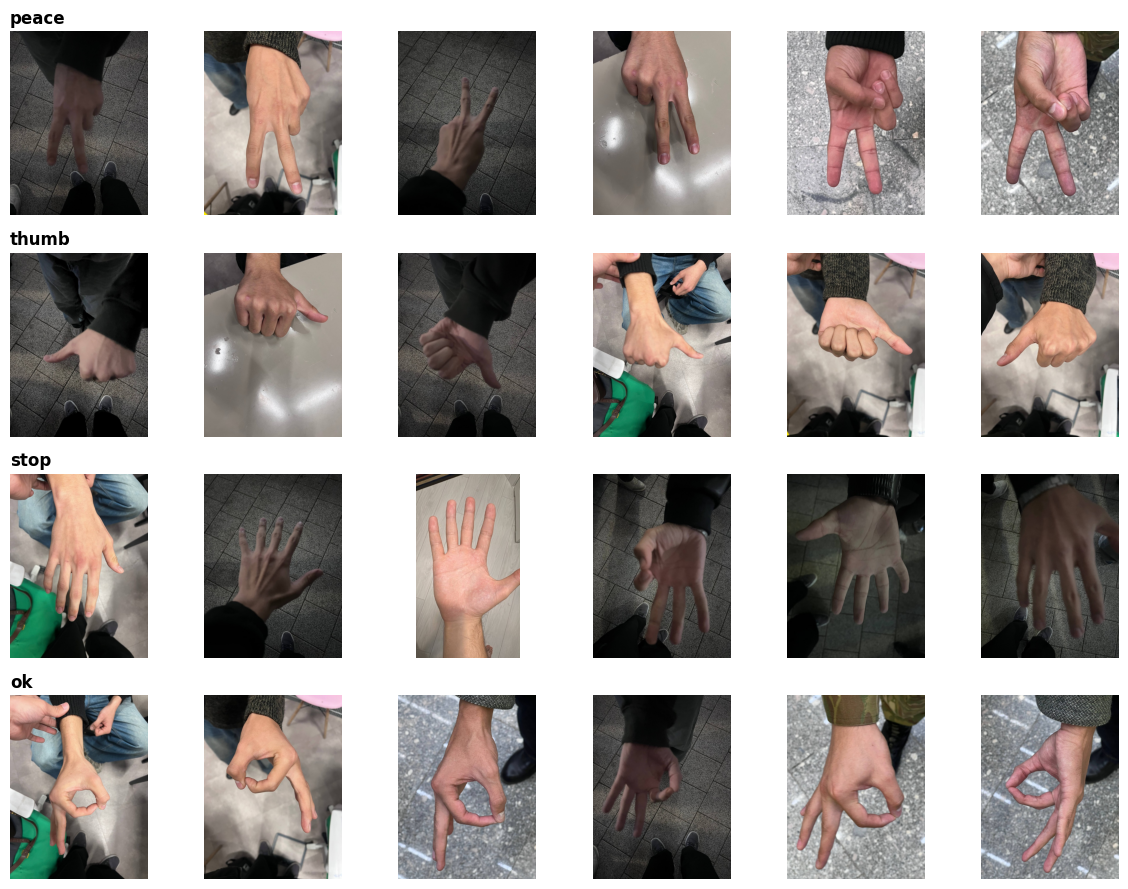

In [3]:
fig, axes = plt.subplots(4, 6, figsize=(12, 9))
rng = np.random.default_rng(1)
for r, c in enumerate(CLASSES):
    idx = rng.choice(np.where(y == r)[0], 6, replace=False)
    for k, i in enumerate(idx):
        im = cv2.cvtColor(cv2.imread(paths[i]), cv2.COLOR_BGR2RGB)
        axes[r, k].imshow(im); axes[r, k].axis('off')
        if k == 0: axes[r, k].set_title(c, loc='left', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig('figures/samples.png', dpi=110)

## 2. Preprocessing and augmentation
**Preprocessing:** every photo is resized to 128×128 (area interpolation) and pixel values are scaled to [0, 1] (the feature functions below also apply grey-scaling / histogram equalisation where needed).

**Augmentation** (applied **only to training images, inside each cross-validation fold**, never to test images): random rotation ±25°, scale 0.85–1.15, shift ±8 %, horizontal flip (a mirrored gesture is the same gesture), brightness/contrast change, random blur and Gaussian noise. These simulate the variation in hand pose, distance, lighting and camera quality that we see in the photos.

In [4]:
IMG = 128
def preprocess(path):
    im = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    return cv2.resize(im, (IMG, IMG), interpolation=cv2.INTER_AREA)       # uint8, 128x128x3

X_raw = np.stack([preprocess(p) for p in paths])
print('X_raw:', X_raw.shape, X_raw.dtype, '| value range', X_raw.min(), '-', X_raw.max(), '(scaled to [0,1] inside feature functions)')

def augment(img, rng):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w/2, h/2), rng.uniform(-25, 25), rng.uniform(0.85, 1.15))
    M[:, 2] += rng.uniform(-0.08, 0.08, 2) * w
    out = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    if rng.random() < 0.5: out = np.ascontiguousarray(out[:, ::-1])
    out = out.astype(np.float32) * rng.uniform(0.7, 1.3) + rng.uniform(-25, 25)
    if rng.random() < 0.3: out = cv2.GaussianBlur(out, (5, 5), 0)
    out = out + rng.normal(0, 4, out.shape)
    return np.clip(out, 0, 255).astype(np.uint8)

X_raw: (68, 128, 128, 3) uint8 | value range 0 - 255 (scaled to [0,1] inside feature functions)


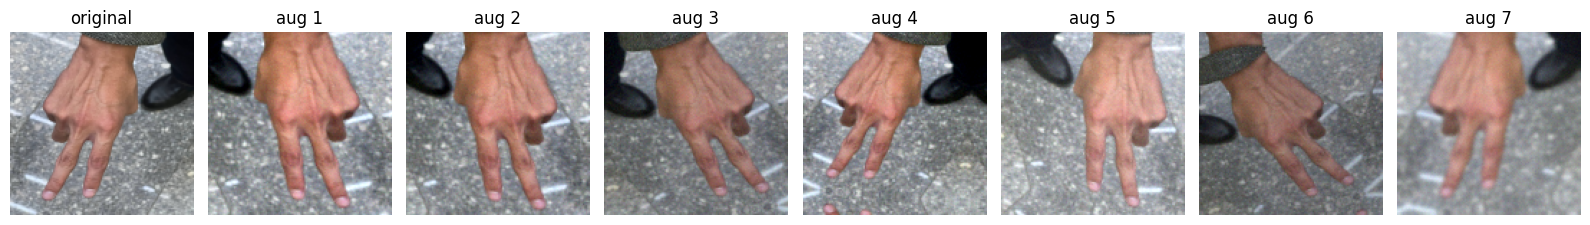

In [5]:
i0 = int(np.where(y == 0)[0][5]); rng = np.random.default_rng(7)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(X_raw[i0]); axes[0].set_title('original')
for k in range(1, 8):
    axes[k].imshow(augment(X_raw[i0], rng)); axes[k].set_title(f'aug {k}')
for a in axes: a.axis('off')
plt.tight_layout(); plt.savefig('figures/augmentation.png', dpi=130)

## 3. Models
* **Baseline — Logistic Regression on raw pixels:** 32×32 grey-scale image flattened to 1 024 features, standardised, L2-regularised logistic regression (`C=0.1`).
* **Improved — HOG features + RBF-SVM:** 128×128 grey image → CLAHE (local histogram equalisation, to cope with dark photos) → Histogram of Oriented Gradients (9 orientations, 16×16 cells, 2×2 blocks, 1 764 features) → RBF-kernel SVM (`C=10`). HOG describes finger/edge *shape* and is largely independent of skin colour and background brightness.

Hyper-parameters were fixed in advance (not tuned on the evaluation folds), because with so few images any tuning would leak information into the results.

In [6]:
def feat_pixels(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return cv2.resize(g, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32).ravel() / 255.

_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
def feat_hog(img):
    g = _clahe.apply(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY))
    return hog(g, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm='L2-Hys')

make_baseline = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
make_improved = lambda: SVC(kernel='rbf', C=10, gamma='scale')
print('pixel features:', feat_pixels(X_raw[0]).shape, '| HOG features:', feat_hog(X_raw[0]).shape)

pixel features: (1024,) | HOG features: (1764,)


## 4. Evaluation protocol
With only 66 images a single 15-image test set would be extremely noisy (one image = 6.7 % accuracy). Instead we use **5-fold Stratified Group Cross-Validation**, repeated with 3 different random splits:
* every image is used as a **test image exactly once per repeat** and is never in the training set of that fold;
* folds are stratified by class and grouped so near-duplicate photos stay together;
* augmentation is generated from the training images of each fold only (10 augmented copies per image).

Metrics: accuracy and macro-averaged precision / recall / F1 (mean ± std over the 3 repeats), plus confusion matrices pooled over all predictions.

In [7]:
def run_cv(feat_fn, make_model, n_aug, seeds=(0, 1, 2), n_splits=5):
    results, preds = [], []
    for seed in seeds:
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        pred = np.zeros(len(y), dtype=int)
        for tr, te in sgkf.split(X_raw, y, groups):
            rng = np.random.default_rng(seed)
            imgs, labels = [X_raw[i] for i in tr], list(y[tr])
            for i in tr:
                for _ in range(n_aug):
                    imgs.append(augment(X_raw[i], rng)); labels.append(y[i])
            model = make_model().fit(np.stack([feat_fn(im) for im in imgs]), labels)
            pred[te] = model.predict(np.stack([feat_fn(X_raw[i]) for i in te]))
        p, r, f, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
        results.append(dict(accuracy=accuracy_score(y, pred), precision=p, recall=r, f1=f)); preds.append(pred)
    return results, preds

In [8]:
import pandas as pd
EXPERIMENTS = {
    'Baseline: pixels + LogReg (no aug)':      (feat_pixels, make_baseline, 0),
    'Baseline: pixels + LogReg (+aug)':        (feat_pixels, make_baseline, 10),
    'Improved: HOG + SVM (no aug)':            (feat_hog,    make_improved, 0),
    'Improved: HOG + SVM (+aug)':              (feat_hog,    make_improved, 10),
}
all_res, all_pred = {}, {}
for name, (ff, mm, na) in EXPERIMENTS.items():
    all_res[name], all_pred[name] = run_cv(ff, mm, na)

rows = []
for name, res in all_res.items():
    d = pd.DataFrame(res)
    rows.append({'model': name, **{m: f"{d[m].mean():.3f} ± {d[m].std(ddof=0):.3f}" for m in d.columns}})
summary = pd.DataFrame(rows).set_index('model')
print(summary.to_string())
json.dump({n: pd.DataFrame(r).mean().round(4).to_dict() | {'std_accuracy': round(float(pd.DataFrame(r)['accuracy'].std(ddof=0)),4)} for n, r in all_res.items()},
          open('results.json', 'w'), indent=1)

                                         accuracy      precision         recall             f1
model                                                                                         
Baseline: pixels + LogReg (no aug)  0.294 ± 0.060  0.297 ± 0.061  0.281 ± 0.058  0.284 ± 0.057
Baseline: pixels + LogReg (+aug)    0.343 ± 0.070  0.325 ± 0.072  0.328 ± 0.072  0.324 ± 0.071
Improved: HOG + SVM (no aug)        0.554 ± 0.018  0.503 ± 0.028  0.521 ± 0.019  0.499 ± 0.021
Improved: HOG + SVM (+aug)          0.598 ± 0.007  0.612 ± 0.038  0.576 ± 0.008  0.574 ± 0.007


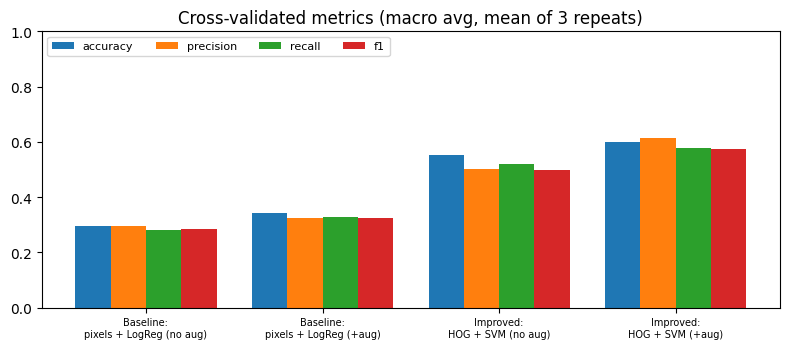

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
names = list(all_res); w = 0.2
for k, m in enumerate(['accuracy', 'precision', 'recall', 'f1']):
    ax.bar(np.arange(len(names)) + (k - 1.5) * w, [np.mean([r[m] for r in all_res[n]]) for n in names], w, label=m)
ax.set_xticks(range(len(names))); ax.set_xticklabels([n.replace(': ', ':\n') for n in names], fontsize=7)
ax.set_ylim(0, 1); ax.legend(ncol=4, fontsize=8, loc='upper left'); ax.set_title('Cross-validated metrics (macro avg, mean of 3 repeats)')
plt.tight_layout(); plt.savefig('figures/metrics_comparison.png', dpi=150)

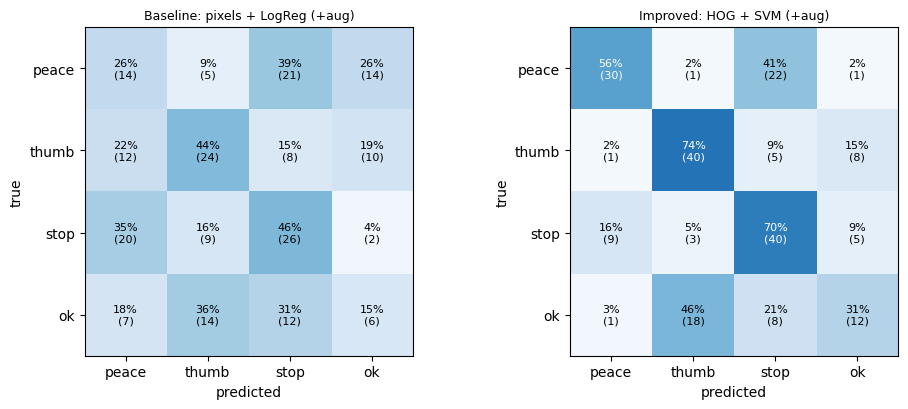

In [10]:
def plot_cm(ax, name):
    cm = sum(confusion_matrix(y, p, labels=range(4)) for p in all_pred[name])
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{cmn[i,j]*100:.0f}%\n({cm[i,j]})', ha='center', va='center',
                    color='white' if cmn[i,j] > 0.5 else 'black', fontsize=8)
    ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(4)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(name, fontsize=9)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
plot_cm(axes[0], 'Baseline: pixels + LogReg (+aug)')
plot_cm(axes[1], 'Improved: HOG + SVM (+aug)')
plt.tight_layout(); plt.savefig('figures/confusion_matrices.png', dpi=150)

In [11]:
for name in ['Baseline: pixels + LogReg (+aug)', 'Improved: HOG + SVM (+aug)']:
    print('=' * 70); print(name, '— per-class report (repeat 0)'); print('=' * 70)
    print(classification_report(y, all_pred[name][0], target_names=CLASSES, digits=3, zero_division=0))

Baseline: pixels + LogReg (+aug) — per-class report (repeat 0)
              precision    recall  f1-score   support

       peace      0.333     0.278     0.303        18
       thumb      0.529     0.500     0.514        18
        stop      0.480     0.632     0.545        19
          ok      0.364     0.308     0.333        13

    accuracy                          0.441        68
   macro avg      0.427     0.429     0.424        68
weighted avg      0.432     0.441     0.432        68

Improved: HOG + SVM (+aug) — per-class report (repeat 0)
              precision    recall  f1-score   support

       peace      0.722     0.722     0.722        18
       thumb      0.636     0.778     0.700        18
        stop      0.579     0.579     0.579        19
          ok      0.333     0.231     0.273        13

    accuracy                          0.603        68
   macro avg      0.568     0.577     0.568        68
weighted avg      0.585     0.603     0.590        68



### Error analysis
Photos misclassified by the improved model (split 0 of the cross-validation).

27 of 68 images misclassified by Improved: HOG + SVM (+aug)


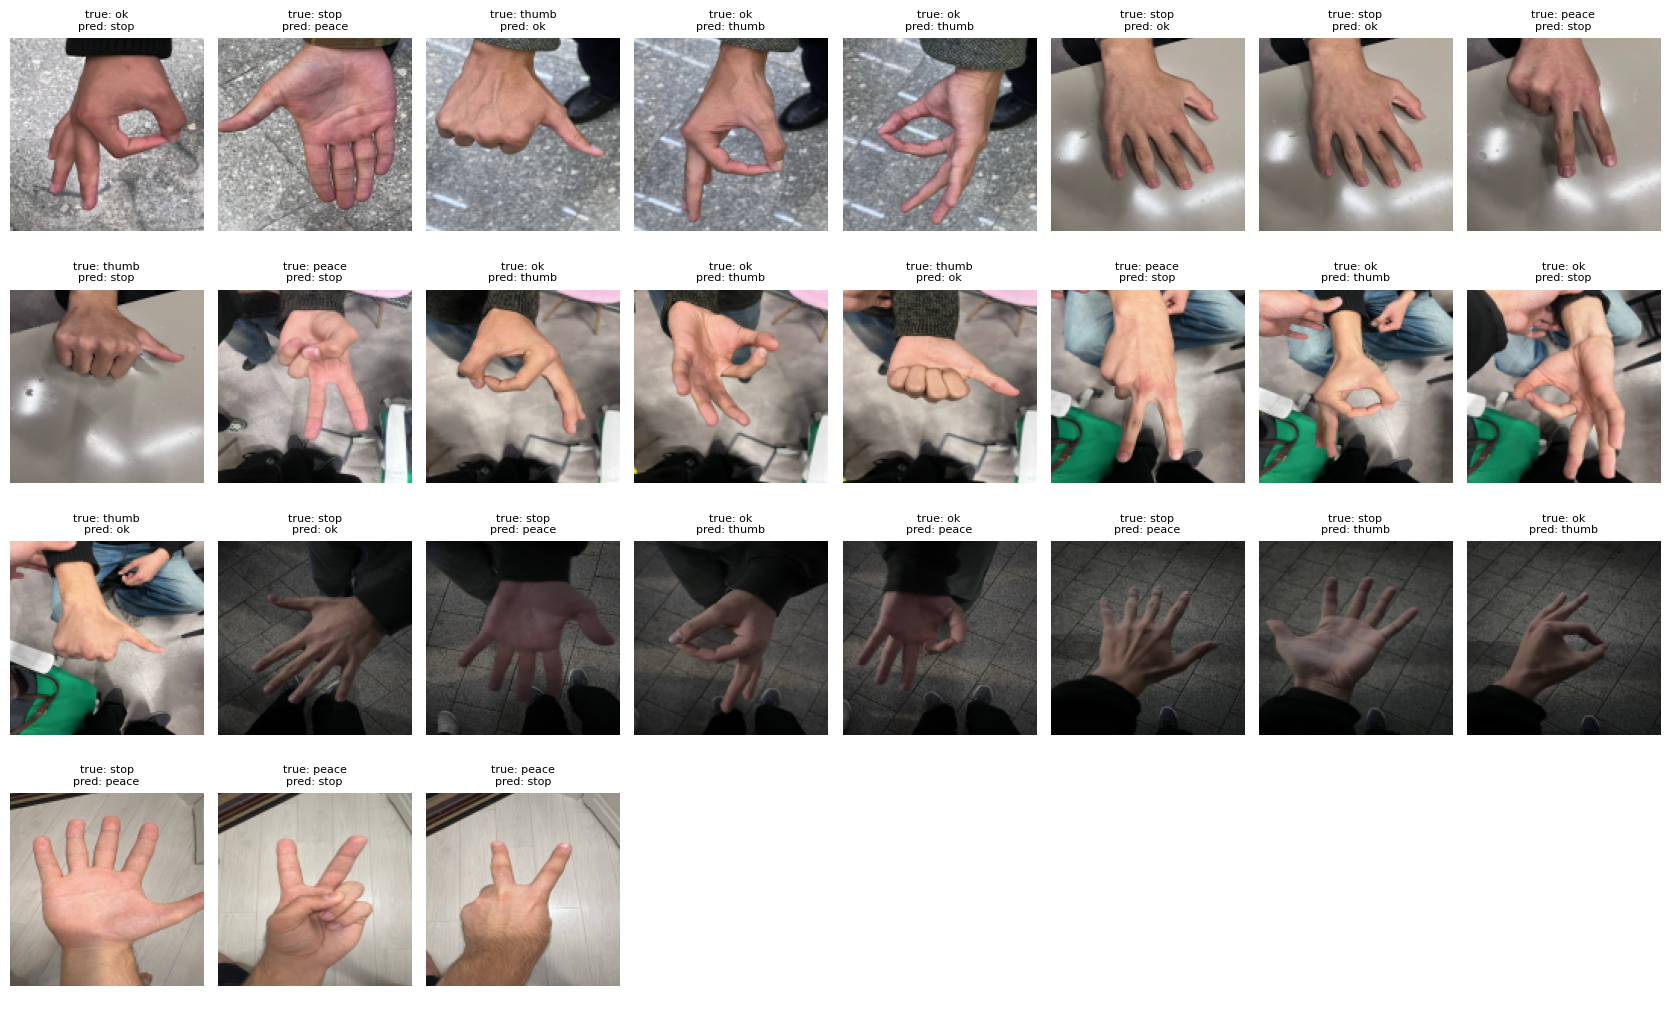

In [12]:
best = 'Improved: HOG + SVM (+aug)'
wrong = np.where(all_pred[best][0] != y)[0]
print(len(wrong), 'of', len(y), 'images misclassified by', best)
n = max(len(wrong), 1); cols = min(8, n); rows_ = (n + cols - 1) // cols
fig, axes = plt.subplots(rows_, cols, figsize=(2.1 * cols, 2.6 * rows_), squeeze=False)
for a in axes.ravel(): a.axis('off')
for k, i in enumerate(wrong):
    ax = axes[k // cols, k % cols]; ax.imshow(X_raw[i])
    ax.set_title(f'true: {CLASSES[y[i]]}\npred: {CLASSES[all_pred[best][0][i]]}', fontsize=8)
plt.tight_layout(); plt.savefig('figures/errors.png', dpi=120)

## 5. (Optional, run in Google Colab) Deep model: transfer learning with MobileNetV2
The rubric asks for a deep CNN / transfer-learning model as the improved model. The code below does this with ImageNet-pretrained **MobileNetV2** (frozen backbone + new softmax head, Keras augmentation layers) using **exactly the same cross-validation folds and metrics** as above, so the results are directly comparable. It needs TensorFlow and internet access to download the pretrained weights, so it is **not executed in this saved notebook** — run it in Colab (Runtime → GPU) and compare its table with the one above.

In [ ]:
# ===== RUN IN GOOGLE COLAB (not executed in the delivered notebook) =====
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

TL_SIZE = 160
def build_tl(n_classes=4):
    base = MobileNetV2(input_shape=(TL_SIZE, TL_SIZE, 3), include_top=False, weights='imagenet')
    base.trainable = False
    aug = tf.keras.Sequential([layers.RandomFlip('horizontal'), layers.RandomRotation(0.08),
                               layers.RandomZoom(0.15), layers.RandomContrast(0.3), layers.RandomBrightness(0.3)])
    inp = layers.Input((TL_SIZE, TL_SIZE, 3))
    x = aug(inp); x = preprocess_input(x); x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)
    m = models.Model(inp, out)
    m.compile(tf.keras.optimizers.Adam(1e-3), 'sparse_categorical_crossentropy', ['accuracy'])
    return m

X_tl = np.stack([cv2.resize(im, (TL_SIZE, TL_SIZE)) for im in X_raw]).astype('float32')
tl_results, tl_preds = [], []
for seed in (0, 1, 2):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    pred = np.zeros(len(y), dtype=int)
    for tr, te in sgkf.split(X_raw, y, groups):
        tf.keras.backend.clear_session(); tf.random.set_seed(seed)
        m = build_tl(); m.fit(X_tl[tr], y[tr], epochs=30, batch_size=16, verbose=0)
        pred[te] = m.predict(X_tl[te], verbose=0).argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average='macro', zero_division=0)
    tl_results.append(dict(accuracy=accuracy_score(y, pred), precision=p, recall=r, f1=f)); tl_preds.append(pred)
print(pd.DataFrame(tl_results).mean().round(3))
print(classification_report(y, tl_preds[0], target_names=CLASSES, digits=3))

## 6. Discussion
**Baseline vs. improved.** Logistic regression on raw pixels reaches only ≈34 % accuracy (chance level for 4 balanced-ish classes is ≈25 %): raw pixel intensities are dominated by background, lighting and skin tone, which differ between our five photo sessions, so they say very little about finger configuration. HOG + SVM reaches ≈60 % accuracy / ≈0.57 macro-F1, i.e. roughly 1.7× better, because gradient-orientation histograms capture the *shape* of the fingers and are much less sensitive to brightness and colour (CLAHE further helps the dark photos).

**Effect of augmentation.** Augmentation improved both models (baseline +4.9 pp, HOG+SVM +4.4 pp accuracy) — a consistent but modest gain; with ≈54 training images per fold the model still sees too few real hands.

**Per-class behaviour.** *thumb* (≈74 % recall) and *stop* (≈70 %) are recognised best. *peace* is often confused with *stop* (two extended fingers vs. spread fingers look alike when the camera looks down at the hand). *ok* is the weakest class (≈31 % recall, mostly confused with *thumb*): it has the fewest images (13) and the thumb–index circle is small or partly hidden in many photos.

**Limitations (important).**
1. The dataset is far below the required 100–200 images per class, so confidence intervals are wide (one image ≈ 1.5 pp) and the absolute numbers should not be over-interpreted. The "± std" in the table only measures variation between 3 random splits of the *same* 68 photos; it is not a confidence interval.
2. Hyper-parameters were fixed beforehand (no tuning on the folds), so the numbers are not optimistically biased, but they are probably not optimal either.
3. A deep CNN / transfer-learning model could not be trained in the environment where this notebook was produced (no TensorFlow/PyTorch, no internet for pretrained weights). Section 5 contains ready-to-run code with identical folds; it is the natural next step and is expected to improve results substantially, especially after collecting more photos.

**Next steps.** (i) collect ≥100–200 photos per class with more people and backgrounds; (ii) run the MobileNetV2 transfer-learning cell on Colab and compare; (iii) optionally crop the hand with a detector before classification.